<a href="https://colab.research.google.com/github/WVF-1/Audience-Analytics/blob/main/FULPs_LLM_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FULPs LLM V1 — Inference-Budget Scheduling (Qwen2.5-0.5B-Instruct on ARC-Challenge)

Adapter that puts the **existing FULPs V2 scheduler** (Thompson Sampling + MED + cumulative cost bookkeeping) on top of a small LLM.
Questions are graph nodes; an "extra pass" is re-scoring a question with its answer options in a different order.

**How to run:** edit only `Config` below. Run top to bottom. In `llm` mode, stop after the **Pilot** cell and read its printout before the full run.
`MODE="mock"` runs the entire pipeline on synthetic data (smoke test only; every figure is then labeled MOCK).

Three kinds of cost are kept separate throughout: **live inference latency** (measured when the cache is built), **cached replay** (scheduler experiments re-run on stored results, seconds), and **estimated compute** (pass counts priced with measured latency).

## 1. Setup

In [1]:
# Colab has torch preinstalled; these are the only extras.
!pip install -q transformers datasets accelerate scipy pandas matplotlib

In [2]:
import os, time, json, math
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import binomtest, chi2_contingency

T_NOTEBOOK_START = time.perf_counter()   # for end-to-end runtime accounting


@dataclass
class Config:
    """Every experimental setting lives here (reproducibility record)."""
    MODE: str = os.environ.get("FULPS_MODE", "llm")   # "llm" = real inference, "mock" = synthetic smoke test
    # --- model / data ---
    MODEL_NAME: str = "Qwen/Qwen2.5-0.5B-Instruct"
    DATASET: str = "allenai/ai2_arc"
    SUBSET: str = "ARC-Challenge"
    SPLIT: str = "test"
    N_PILOT: int = 40            # pilot size: measures latency, prompt sanity, projected run time
    N_QUESTIONS: int = 400       # set after reading the pilot (full 4-option test split is ~1,100)
    SAMPLE_SEED: int = 0
    BATCH_SIZE: int = 10         # prompts per forward pass (latency is amortized over the batch)
    N_EXTRA_PASSES: int = 4      # refinements available per question (pass 0 is the baseline)
    # --- graph / attention ---
    KNN_K: int = 5
    ATTN_HIDDEN: int = 32
    ATTN_SEED: int = 0
    # --- scheduling experiments ---
    BUDGET_LEVELS: tuple = (0.05, 0.10, 0.20, 0.40, 0.80)   # fraction of the FULL extra-pass allocation
    PRIMARY_BUDGET: float = 0.20                            # pre-specified level for the primary tests
    N_SCHED_SEEDS: int = 20      # scheduler seeds (replay of cached inference, NOT independent model runs)
    LABELFREE_TAU: float = 0.02  # entropy-change threshold for the label-free reward categories
    N_BOOT: int = 2000
    BOOT_SEED: int = 0
    OUT_DIR: str = "FULPs_LLM_V1"


CFG = Config()
assert CFG.PRIMARY_BUDGET in CFG.BUDGET_LEVELS
os.makedirs(os.path.join(CFG.OUT_DIR, "figures"), exist_ok=True)
print(json.dumps(asdict(CFG), indent=2))

{
  "MODE": "llm",
  "MODEL_NAME": "Qwen/Qwen2.5-0.5B-Instruct",
  "DATASET": "allenai/ai2_arc",
  "SUBSET": "ARC-Challenge",
  "SPLIT": "test",
  "N_PILOT": 40,
  "N_QUESTIONS": 400,
  "SAMPLE_SEED": 0,
  "BATCH_SIZE": 10,
  "N_EXTRA_PASSES": 4,
  "KNN_K": 5,
  "ATTN_HIDDEN": 32,
  "ATTN_SEED": 0,
  "BUDGET_LEVELS": [
    0.05,
    0.1,
    0.2,
    0.4,
    0.8
  ],
  "PRIMARY_BUDGET": 0.2,
  "N_SCHED_SEEDS": 20,
  "LABELFREE_TAU": 0.02,
  "N_BOOT": 2000,
  "BOOT_SEED": 0,
  "OUT_DIR": "FULPs_LLM_V1"
}


## 2. Original FULPs implementation (copied verbatim from `gnn_scheduler_v2_colab_final.ipynb`)

These two cells are the original `scheduler.py` and `GATAttentionScorer`, **unmodified**. Nothing below re-implements MED, BEU, cost, smoothing, or the selection blend.

**Review findings that shape this adapter** (verified against the code, see audit cell in section 7):
- `BEU = U − λC` with **λ = 0.1** (the spec draft omitted λ). With the extra `−0.10·C` in MED, the effective weights are U: 0.55, A: 0.35, C: 0.12.
- Laplace smoothing is `(MED+α)/(1+α)`, an increasing affine map that `select_nodes` then removes by min-max normalizing. It has **no effect on selection**; starvation protection comes only from the Thompson term.
- `A_i` is the mean of softmax weights over node *i*'s neighborhood, which always equals **1/deg(i)** whatever the attention parameters are. They are also never trained (the scorer runs under `no_grad`, loss never touches it). So `A_i` is an inverse-degree signal, not learned attention. Its softmax also subtracts the *global* max score, so large hidden-state scales make `A_i` underflow toward 0; the adapter unit-normalizes hidden states to avoid this.
- `ThompsonSampler.select_nodes` samples `np.random.beta` inline, so the Dirichlet reward needs a small subclass (section 7).

In [3]:
# ===== ORIGINAL scheduler.py cell (verbatim) =====
# ============================================================
# Scheduler V0 (Frozen)
# ------------------------------------------------------------
# This file defines the Thompson Sampling decision engine used
# by the scheduled GCN experiments.
#
# IMPORTANT:
# This scheduler ONLY decides which nodes deserve additional
# computation. It does NOT perform message passing itself.
#
# The execution of additional computation is handled inside the
# training loop.
# ============================================================

# ---------- Fixed constants ----------
LAMBDA = 0.10      # Bayesian Expected Utility cost penalty
ALPHA = 0.01       # Laplace smoothing
MED_WEIGHTS = dict(
    attention=0.35,
    uncertainty=0.35,
    beu=0.20,
    cost=0.10,
)


# ============================================================
# Uncertainty
# ============================================================

def compute_uncertainty(logits):
    """
    Predictive entropy.

    U_i = -Σ p_i log(p_i)

    Higher entropy means the classifier is less certain.
    """
    probs = F.softmax(logits, dim=-1)
    log_probs = torch.log(probs.clamp_min(1e-12))
    entropy = -(probs * log_probs).sum(dim=-1)
    return entropy


# ============================================================
# Cost bookkeeping
# ============================================================

class CostTracker:
    """
    Records C_i = number of times this node has been SELECTED for an
    extra pass so far (1st selection -> C_i=1, 2nd -> C_i=2, ...) --
    matching the original spec exactly.

    This deliberately does NOT track how many epochs an extra pass stays
    "in force" once selected (that's real compute, and it's tracked
    separately -- and unaffected -- by BudgetTracker below, for
    reporting). Conflating those two things was the bug: charging cost
    every epoch a selection persisted (instead of once per selection
    event) inflated C_i ~5x per selection (matching reconsider_every),
    which permanently buried any node's MED score after just one
    selection and made genuine repeat-selection of persistently-hard
    nodes essentially impossible -- Thompson Sampling's belief updates
    never got a chance to matter because this dominated the ranking.
    """

    def __init__(self, num_nodes):
        self.cost = np.zeros(num_nodes, dtype=np.float32)

    def register_selection(self, node_indices):
        """Call ONCE per reconsideration, for the nodes just selected."""
        idx = np.asarray(node_indices, dtype=np.int64)
        if idx.size == 0:
            return
        self.cost[idx] += 1

    def get_cost(self):
        return torch.tensor(self.cost, dtype=torch.float32)

    def reset(self):
        self.cost[:] = 0


# ============================================================
# Budget bookkeeping
# ============================================================

class BudgetTracker:
    """
    Pure bookkeeping.

    Records computational budget spent per node.

    Budget NEVER affects scheduling decisions.
    It exists solely for reporting and analysis.
    """

    def __init__(self, num_nodes):
        self.budget = np.zeros(num_nodes, dtype=np.float32)

    def spend(self, node_indices, amount=1.0):
        # Vectorized for the same reason as CostTracker.register_pass above.
        idx = np.asarray(node_indices, dtype=np.int64)
        if idx.size == 0:
            return
        self.budget[idx] += amount

    @property
    def total_budget(self):
        return float(self.budget.sum())

    @property
    def avg_budget_per_node(self):
        return float(self.budget.mean())


# ============================================================
# Bayesian Expected Utility
# ============================================================

def compute_beu(uncertainty, cost, lam=LAMBDA):
    """
    Bayesian Expected Utility approximation.

    BEU_i = U_i - λ C_i
    """
    return uncertainty - lam * cost


# ============================================================
# Meditation score
# ============================================================

def compute_med(attention, uncertainty, beu, cost,
                weights=MED_WEIGHTS):
    """
    Meditation score.

    MED_i =
        0.35 * Attention
      + 0.35 * Uncertainty
      + 0.20 * BEU
      - 0.10 * Cost
    """

    return (
        weights["attention"] * attention
        + weights["uncertainty"] * uncertainty
        + weights["beu"] * beu
        - weights["cost"] * cost
    )


# ============================================================
# Laplace smoothing
# ============================================================

def laplace_smooth(med, alpha=ALPHA):
    """
    Laplace smoothing.

    Prevents starvation by ensuring every node retains a
    non-zero scheduling probability.

    MED' = (MED + α)/(1 + α)
    """
    return (med + alpha) / (1.0 + alpha)


# ============================================================
# Thompson Sampling
# ============================================================

class ThompsonSampler:
    """
    Thompson Sampling decision engine.

    Every node is treated as a multi-armed bandit arm.

    Thompson Sampling provides exploration.

    MED provides exploitation.

    IMPORTANT:
    This class ONLY decides which nodes should receive
    additional computation.

    It does NOT execute message passing.

    The training loop is responsible for turning these
    scheduling decisions into additional computation.
    """

    def __init__(self,
                 num_nodes,
                 prior_alpha=1.0,
                 prior_beta=1.0):

        self.alpha = np.full(num_nodes,
                             prior_alpha,
                             dtype=np.float32)

        self.beta = np.full(num_nodes,
                            prior_beta,
                            dtype=np.float32)

    def select_nodes(self,
                     med_scores,
                     budget_fraction=0.10,
                     budget_count=None):
        """
        Decide which nodes deserve additional computation.

        budget_fraction: select this fraction of ALL nodes (scales with
            graph size -- selected count grows as n grows).

        budget_count: if provided, overrides budget_fraction and selects
            this many nodes in absolute terms, regardless of graph size.
            This is the parameter that actually determines whether the
            subgraph-restricted extra pass stays computationally local at
            scale: a FIXED absolute selection count keeps the union of
            selected nodes' neighborhoods a shrinking fraction of the
            graph as n grows. A fraction-based count (budget_fraction)
            grows the selected set proportionally to n, so its 1-hop
            neighborhood sweeps up most of the graph regardless of how
            sparse the graph is -- this was empirically confirmed to be
            the actual driver of the wall-clock/budget mismatch, not graph
            density as originally hypothesized.

        Returns
        -------
        selected_nodes
            Indices chosen by Thompson Sampling.

        combined_scores
            Final Thompson + MED ranking score.

        med_normalized
            Normalized MED values (useful for plotting/debugging).
        """

        med_scores = med_scores.detach().cpu().numpy()

        sampled = np.random.beta(self.alpha,
                                 self.beta)

        # Normalize MED
        med_norm = (
            med_scores - med_scores.min()
        ) / (
            med_scores.max()
            - med_scores.min()
            + 1e-12
        )

        # Exploration / exploitation tradeoff
        gamma = 0.50

        combined = (
            (1.0 - gamma) * sampled
            + gamma * med_norm
        )

        if budget_count is not None:
            k = max(1, int(budget_count))
        else:
            k = max(
                1,
                int(len(combined) * budget_fraction)
            )

        selected = np.argsort(combined)[-k:]

        return selected, combined, med_norm

    def update_from_outcome(self,
                            node_indices,
                            reward,
                            threshold=0.0):
        """
        Update Beta beliefs using a MEASURED OUTCOME, not agreement with
        MED.

        This replaces the old update(selected_nodes, med_scores) method,
        which rewarded a node for having above-median MED at the moment
        it was selected -- that was circular: it rewarded the scheduler
        for agreeing with the very heuristic used to select the node in
        the first place, so Thompson Sampling was never learning anything
        MED didn't already encode.

        node_indices: nodes that were selected at a PREVIOUS
            reconsideration and have now had a full persistence window
            (reconsider_every epochs) with the extra pass active -- enough
            time to show whether it actually helped.

        reward: per-node measured benefit from that extra pass (e.g.
            uncertainty_before - uncertainty_after; positive = the node's
            predictive entropy genuinely went down while it had the extra
            layer, i.e. it got MORE confident). Reward > threshold counts
            as a successful pull (alpha += 1); otherwise a failure
            (beta += 1). MED plays no role here at all -- it's purely
            about whether the intervention measurably worked.

        threshold: minimum reward to count as a success. Default 0.0
            (any genuine improvement counts).
        """

        idx = np.asarray(node_indices, dtype=np.int64)
        if idx.size == 0:
            return

        reward = np.asarray(reward, dtype=np.float32)
        success_mask = reward > threshold

        self.alpha[idx[success_mask]] += 1
        self.beta[idx[~success_mask]] += 1

In [4]:
# ===== ORIGINAL GATAttentionScorer (verbatim from model.py cell) =====
class GATAttentionScorer(nn.Module):
    """
    Single-layer GAT-style attention scorer.

    e_ij = LeakyReLU(a^T [Wh_i || Wh_j])
    a_ij = softmax_j(e_ij) over node i's neighborhood

    NOT part of the classification forward pass -- this only produces
    per-node attention scores (A_i) used as scheduling signal in
    scheduler.py. Keeping it separate preserves the constraint that the
    underlying GCN architecture is identical between the baseline and
    scheduled models.
    """

    def __init__(self, in_dim, hidden_dim, negative_slope=0.2):
        super().__init__()
        self.W = nn.Linear(in_dim, hidden_dim, bias=False)
        self.a = nn.Parameter(torch.empty(2 * hidden_dim))
        nn.init.xavier_uniform_(self.a.unsqueeze(0))
        self.leaky_relu = nn.LeakyReLU(negative_slope)

    def forward(self, h, edge_index):
        """
        h: [num_nodes, in_dim] node embeddings
        edge_index: [2, num_edges]

        Returns:
            node_attention: [num_nodes] -- A_i, the mean attention node i
                             assigns to its neighbors (V0 aggregation choice;
                             swap for max_j a_ij or attention *received* if
                             you want a different signal later).
        """
        Wh = self.W(h)  # [N, hidden_dim]
        src, dst = edge_index

        edge_feat = torch.cat([Wh[src], Wh[dst]], dim=-1)  # [E, 2*hidden_dim]
        e = self.leaky_relu(edge_feat @ self.a)  # [E]

        a_ij = self._softmax_per_node(e, src, num_nodes=h.size(0))
        node_attention = self._scatter_mean(a_ij, src, num_nodes=h.size(0))

        return node_attention

    @staticmethod
    def _softmax_per_node(e, index, num_nodes):
        """Softmax of e_ij grouped by source node i (numerically stable)."""
        e = e - e.max()
        exp_e = torch.exp(e)
        denom = torch.zeros(num_nodes, device=e.device).scatter_add_(0, index, exp_e)
        denom = denom[index].clamp_min(1e-12)
        return exp_e / denom

    @staticmethod
    def _scatter_mean(values, index, num_nodes):
        sums = torch.zeros(num_nodes, device=values.device).scatter_add_(0, index, values)
        counts = torch.zeros(num_nodes, device=values.device).scatter_add_(
            0, index, torch.ones_like(values)
        )
        counts = counts.clamp_min(1)
        return sums / counts

## 3. Benchmark, permutations, and answer mapping  *(new, LLM-specific)*

- ARC-Challenge test, **4-option questions only**, options relabeled A–D by position, fixed random sample (`SAMPLE_SEED`).
- Pass 0 is the original option order (the baseline). Passes 1–4 are four predefined, distinct, non-identity permutations (three cyclic shifts and a reversal), **identical for every question and every arm**.
- Letter probabilities are **always remapped to original option identities before averaging**. Aggregate after *t* refinements = mean of the remapped distributions of passes 0..*t*.

In [5]:
LETTERS = "ABCD"

# PERMS[t][j] = index of the ORIGINAL option shown at letter position j on pass t.
PERMS = np.array([[0, 1, 2, 3],      # pass 0: identity (baseline pass)
                  [1, 2, 3, 0],      # pass 1: cyclic shift
                  [2, 3, 0, 1],      # pass 2: cyclic shift
                  [3, 0, 1, 2],      # pass 3: cyclic shift
                  [3, 2, 1, 0]])     # pass 4: reversal
N_PASSES = len(PERMS)
assert N_PASSES == CFG.N_EXTRA_PASSES + 1
assert len({tuple(p) for p in PERMS}) == N_PASSES, "initial pass must not be duplicated among refinements"


def remap_to_original(p_letter, perm):
    """Letter-position probabilities -> original-option probabilities."""
    out = np.zeros_like(p_letter)
    out[perm] = p_letter          # option perm[j] was shown at letter j
    return out


# unit test: option originally 'B' (index 1) shown as letter A on this pass
assert np.allclose(remap_to_original(np.array([.1, .2, .3, .4]), np.array([1, 2, 3, 0])), [.4, .1, .2, .3])


def load_arc_questions(cfg):
    from datasets import load_dataset
    ds = load_dataset(cfg.DATASET, cfg.SUBSET, split=cfg.SPLIT)
    print("dataset fingerprint:", getattr(ds, "_fingerprint", "n/a"))
    items = []
    for ex in ds:
        labels, texts = ex["choices"]["label"], ex["choices"]["text"]
        if len(texts) != 4 or ex["answerKey"] not in labels:
            continue
        items.append(dict(id=ex["id"], question=ex["question"], options=list(texts),
                          gold=labels.index(ex["answerKey"])))
    print(f"{len(items)} four-option questions available; sampling {cfg.N_QUESTIONS} (seed {cfg.SAMPLE_SEED})")
    order = np.random.default_rng(cfg.SAMPLE_SEED).permutation(len(items))[:cfg.N_QUESTIONS]
    return [items[i] for i in order]

## 4. Model backend  *(new)*

Answer probabilities come from one forward pass: next-token logits at the end of a chat prompt, restricted to the tokens `A B C D` and softmaxed. The hidden state is the final-layer, last-token vector. Only the last position goes through `lm_head` (avoids materializing full-vocabulary logits).

In [6]:
def build_prompt(tok, question, options, perm):
    body = question.strip() + "\n\n" + "\n".join(
        f"{LETTERS[j]}. {options[perm[j]].strip()}" for j in range(4))
    msgs = [{"role": "system", "content": "You are a careful science exam taker."},
            {"role": "user", "content": "Answer the multiple-choice question. Respond with only the letter "
                                        "(A, B, C, or D) of the correct option.\n\n" + body}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)


class LLMBackend:
    def __init__(self, cfg):
        from transformers import AutoTokenizer, AutoModelForCausalLM
        if torch.cuda.is_available():
            self.device, self.dtype = "cuda", torch.float16
        elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
            self.device, self.dtype = "mps", torch.float16
        else:
            self.device, self.dtype = "cpu", torch.float32
        self.tok = AutoTokenizer.from_pretrained(cfg.MODEL_NAME, padding_side="left")
        try:
            model = AutoModelForCausalLM.from_pretrained(cfg.MODEL_NAME, dtype=self.dtype)
        except TypeError:   # older transformers
            model = AutoModelForCausalLM.from_pretrained(cfg.MODEL_NAME, torch_dtype=self.dtype)
        self.model = model.to(self.device).eval()
        ids = [self.tok.encode(l, add_special_tokens=False) for l in LETTERS]
        assert all(len(x) == 1 for x in ids), "answer letters must be single tokens"
        self.letter_ids = [x[0] for x in ids]
        self.n_params = sum(p.numel() for p in self.model.parameters())

    def _sync(self):
        if self.device == "cuda": torch.cuda.synchronize()
        elif self.device == "mps": torch.mps.synchronize()

    @torch.inference_mode()
    def run_prompts(self, prompts):
        enc = self.tok(prompts, return_tensors="pt", padding=True).to(self.device)
        self._sync(); t0 = time.perf_counter()
        last = self.model.model(**enc).last_hidden_state[:, -1, :]      # [B, D], after final norm
        logits = self.model.lm_head(last).float()                       # [B, vocab]
        self._sync(); dt = time.perf_counter() - t0
        mass = F.softmax(logits, -1)[:, self.letter_ids].sum(-1)        # prompt sanity: mass on A-D
        p_letter = F.softmax(logits[:, self.letter_ids], -1)
        return (p_letter.cpu().numpy().astype(np.float64), last.float().cpu().numpy(),
                dt / len(prompts), mass.cpu().numpy())


def run_items(backend, items, idxs, rows):
    """Run every pass for each question in idxs (skips ones already in rows). Latency is per prompt,
    amortized over the batch."""
    per = max(1, CFG.BATCH_SIZE // N_PASSES)
    todo = [i for i in idxs if i not in rows]
    t0 = time.perf_counter()
    for s in range(0, len(todo), per):
        chunk = todo[s:s + per]
        prompts = [build_prompt(backend.tok, items[i]["question"], items[i]["options"], PERMS[t])
                   for i in chunk for t in range(N_PASSES)]
        p, h, lat, mass = backend.run_prompts(prompts)
        for a, i in enumerate(chunk):
            sl = slice(a * N_PASSES, (a + 1) * N_PASSES)
            rows[i] = dict(p_orig=np.stack([remap_to_original(p[sl][t], PERMS[t]) for t in range(N_PASSES)]),
                           hidden=h[sl], latency=np.full(N_PASSES, lat), mass=mass[sl])
        if (s // per) % 20 == 0:
            print(f"  {len(rows)} questions done, {time.perf_counter() - t0:.0f}s elapsed")
    return time.perf_counter() - t0


def build_mock_rows(n, seed=0, dim=64):
    """Synthetic stand-in for LLM output (smoke test only). Letter-position bias makes permutation averaging help."""
    rng = np.random.default_rng(seed)
    centers = rng.normal(size=(12, dim)) * 3
    cl, gold = rng.integers(0, 12, n), rng.integers(0, 4, n)
    skill = rng.beta(2, 2, n) * 3.0
    pos_bias = np.array([0.8, 0.2, -0.3, -0.7])
    items = [dict(id=f"mock{i}", question="mock", options=list("wxyz"), gold=int(gold[i])) for i in range(n)]
    rows = {}
    for i in range(n):
        base_h, p_o, hid = centers[cl[i]] + rng.normal(size=dim), [], []
        for t in range(N_PASSES):
            z = np.zeros(4); z[gold[i]] = skill[i]
            lg = (z + rng.normal(scale=0.8, size=4))[PERMS[t]] + pos_bias
            p = np.exp(lg - lg.max()); p /= p.sum()
            p_o.append(remap_to_original(p, PERMS[t])); hid.append(base_h + rng.normal(scale=0.3, size=dim))
        rows[i] = dict(p_orig=np.stack(p_o), hidden=np.stack(hid),
                       latency=np.full(N_PASSES, 0.2 + 0.02 * rng.random()), mass=np.ones(N_PASSES))
    return items, rows

## 5. Pilot — **read this output before the full run**

Check: (1) `mass on A-D` is near 1 (the prompt makes the model answer with a letter), (2) single-pass accuracy is well above 25% chance, (3) the projected full-run time fits your budget. Set `N_QUESTIONS` accordingly and re-run from the Config cell if needed.

In [7]:
ROWS, LIVE_BUILD_S = {}, 0.0
if CFG.MODE == "mock":
    ITEMS, ROWS = build_mock_rows(CFG.N_QUESTIONS)
    print("MOCK MODE: synthetic data, latencies are synthetic, results mean nothing scientifically.")
else:
    ITEMS = load_arc_questions(CFG)
    BACKEND = LLMBackend(CFG)
    print(f"model={CFG.MODEL_NAME}  device={BACKEND.device}  dtype={BACKEND.dtype}  params={BACKEND.n_params/1e6:.0f}M")
    pilot_idx = list(range(min(CFG.N_PILOT, len(ITEMS))))
    LIVE_BUILD_S += run_items(BACKEND, ITEMS, pilot_idx, ROWS)
    pr = [ROWS[i] for i in pilot_idx]
    lat = np.mean([r["latency"][0] for r in pr]); mass = np.mean([r["mass"].mean() for r in pr])
    acc0 = np.mean([np.argmax(r["p_orig"][0]) == ITEMS[i]["gold"] for r, i in zip(pr, pilot_idx)])
    print(f"pilot n={len(pilot_idx)}: mean latency/pass={lat*1000:.0f} ms | mass on A-D={mass:.3f} | single-pass acc={acc0:.3f}")
    for n_proj in (CFG.N_QUESTIONS, 1100):
        print(f"projected cache build for {n_proj} questions x {N_PASSES} passes: ~{n_proj*N_PASSES*lat/60:.1f} min")
    try:
        import psutil; print(f"process RSS now: {psutil.Process().memory_info().rss/1e9:.2f} GB")
    except Exception:
        pass
    if BACKEND.device == "cuda":
        print(f"peak GPU memory: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

README.md:   0%|          | 0.00/9.00k [00:00<?, ?B/s]

ARC-Challenge/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B /  190kB            

ARC-Challenge/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

ARC-Challenge/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B /  204kB            

ARC-Challenge/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

ARC-Challenge/validation-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 55.7kB            

... (11 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

model=Qwen/Qwen2.5-0.5B-Instruct  device=cpu  dtype=torch.float32  params=494M
  2 questions done, 27s elapsed
pilot n=40: mean latency/pass=2115 ms | mass on A-D=0.983 | single-pass acc=0.275
projected cache build for 400 questions x 5 passes: ~70.5 min
projected cache build for 1100 questions x 5 passes: ~193.9 min
process RSS now: 2.91 GB


## 6. Full cache build, graph, and initial signals

The cache stores, per question and pass: remapped answer probabilities, hidden state, and latency. It is saved to disk so scheduler experiments can be replayed without re-running the model.

In [8]:
if CFG.MODE != "mock":
    LIVE_BUILD_S += run_items(BACKEND, ITEMS, list(range(len(ITEMS))), ROWS)
    print(f"cache built for {len(ITEMS)} questions in {LIVE_BUILD_S:.0f}s of live inference")

N = len(ITEMS)
P   = np.stack([ROWS[i]["p_orig"] for i in range(N)])        # [N, passes, 4]  original-option space
HID = np.stack([ROWS[i]["hidden"] for i in range(N)])        # [N, passes, D]
LAT = np.stack([ROWS[i]["latency"] for i in range(N)])       # [N, passes]    measured s/pass
GOLD = np.array([it["gold"] for it in ITEMS])
np.savez_compressed(os.path.join(CFG.OUT_DIR, f"inference_cache_{CFG.MODE}.npz"),
                    P=P, HID=HID, LAT=LAT, GOLD=GOLD, PERMS=PERMS, ids=np.array([it["id"] for it in ITEMS]))

AR = np.arange(N)
# Aggregate after t refinements, in ORIGINAL option space (never raw letters).
AGG = np.cumsum(P, axis=1) / np.arange(1, N_PASSES + 1)[None, :, None]
# Original compute_uncertainty (takes logits). softmax(log p) == p, so log-probs reuse it unchanged.
H = compute_uncertainty(torch.log(torch.tensor(AGG, dtype=torch.float32).clamp_min(1e-12))).numpy()   # [N, passes]
CORRECT = AGG.argmax(-1) == GOLD[:, None]                     # [N, passes] correctness of the aggregate
LATC = np.cumsum(LAT, axis=1)                                 # measured cost after t refinements
BASE_ACC, DEEP_ACC = CORRECT[:, 0].mean(), CORRECT[:, -1].mean()

print(f"N={N} | baseline acc={BASE_ACC:.3f} | deep (all {N_PASSES} passes) acc={DEEP_ACC:.3f}")
print("single-pass acc by permutation (position bias shows here):",
      np.round([(P[:, t].argmax(-1) == GOLD).mean() for t in range(N_PASSES)], 3))
print("mean entropy of aggregate after t refinements:", np.round(H.mean(0), 3))

  42 questions done, 19s elapsed
  82 questions done, 425s elapsed
  122 questions done, 805s elapsed


KeyboardInterrupt: 

In [10]:
# Safely trim ITEMS and update variables to match the partially built cache
completed_indices = sorted(list(ROWS.keys()))
ITEMS = [ITEMS[i] for i in completed_indices]
N = len(ITEMS)

# Re-index ROWS to match the new continuous indices (0 to N-1)
ROWS = {new_idx: ROWS[old_idx] for new_idx, old_idx in enumerate(completed_indices)}

print(f"Successfully trimmed run to {N} completed questions. You can now execute the rest of the notebook safely!")

Successfully trimmed run to 126 completed questions. You can now execute the rest of the notebook safely!


In [13]:
# ---- Reconstruct variables from the completed ROWS cache ----
N = len(ITEMS)
P   = np.stack([ROWS[i]["p_orig"] for i in range(N)])        # [N, passes, 4]  original-option space
HID = np.stack([ROWS[i]["hidden"] for i in range(N)])        # [N, passes, D]
LAT = np.stack([ROWS[i]["latency"] for i in range(N)])       # [N, passes]    measured s/pass
GOLD = np.array([it["gold"] for it in ITEMS])

AR = np.arange(N)
# Aggregate after t refinements, in ORIGINAL option space (never raw letters).
AGG = np.cumsum(P, axis=1) / np.arange(1, N_PASSES + 1)[None, :, None]
# Original compute_uncertainty (takes logits). softmax(log p) == p, so log-probs reuse it unchanged.
H = compute_uncertainty(torch.log(torch.tensor(AGG, dtype=torch.float32).clamp_min(1e-12))).numpy()   # [N, passes]
CORRECT = AGG.argmax(-1) == GOLD[:, None]                     # [N, passes] correctness of the aggregate
LATC = np.cumsum(LAT, axis=1)                                 # measured cost after t refinements
BASE_ACC, DEEP_ACC = CORRECT[:, 0].mean(), CORRECT[:, -1].mean()

print(f"Parsed partial cache variables for N={N} completed questions.")

# ---- Graph construction (once): symmetrized kNN over unit-normalized pass-0 hidden states ----
def build_knn_graph(hidden0, k):
    t0 = time.perf_counter()
    n = len(hidden0)
    Z = hidden0 / np.clip(np.linalg.norm(hidden0, axis=1, keepdims=True), 1e-12, None)   # unit norm (adapter)
    S = Z @ Z.T
    np.fill_diagonal(S, -np.inf)                                    # no self-neighbors
    nbrs = np.argpartition(-S, k - 1, axis=1)[:, :k]                # top-k cosine neighbors per node
    src, dst = np.repeat(np.arange(n), k), nbrs.reshape(-1)         # edge_index[0] = node i (the code softmaxes over src)
    E = np.unique(np.concatenate([np.stack([src, dst]), np.stack([dst, src])], 1), axis=1)   # symmetrize + dedupe
    A = sparse.coo_matrix((np.ones(E.shape[1]), (E[0], E[1])), shape=(n, n)).tocsr()
    A_tilde = A + sparse.eye(n)                                     # self-loops
    d = np.asarray(A_tilde.sum(1)).ravel()
    A_hat = sparse.diags(d ** -0.5) @ A_tilde @ sparse.diags(d ** -0.5)   # symmetric normalization (documentation only:
    return dict(Z=Z, edge_index=torch.tensor(E, dtype=torch.long), A_hat=A_hat,   # nothing in this adapter consumes it)
                deg_out=np.bincount(E[0], minlength=n), seconds=time.perf_counter() - t0)


GRAPH = build_knn_graph(HID[:, 0, :], CFG.KNN_K)
print(f"graph: {N} nodes, {GRAPH['edge_index'].shape[1]} directed edges, "
      f"degree min/median/max = {GRAPH['deg_out'].min()}/{int(np.median(GRAPH['deg_out']))}/{GRAPH['deg_out'].max()}, "
      f"built in {GRAPH['seconds']:.3f}s")

# ---- Original attention scorer, unmodified, never trained (as in the original code) ----
torch.manual_seed(CFG.ATTN_SEED)
attention_model = GATAttentionScorer(GRAPH["Z"].shape[1], CFG.ATTN_HIDDEN)
with torch.no_grad():
    ATT = attention_model(torch.tensor(GRAPH["Z"], dtype=torch.float32), GRAPH["edge_index"])   # A_i

# ---- Attention audit ----
gap = np.abs(ATT.numpy() - 1.0 / GRAPH["deg_out"]).max()
print(f"ATTENTION AUDIT: max |A_i - 1/deg_i| = {gap:.2e}  (attention parameters untrained; A_i is an inverse-degree signal)")
if gap > 1e-4:
    print("  WARNING: A_i departs from 1/deg_i, which means score underflow; check hidden-state scale")
print(f"  distinct A_i values: {len(np.unique(np.round(ATT.numpy(), 6)))}")

Parsed partial cache variables for N=126 completed questions.
graph: 126 nodes, 990 directed edges, degree min/median/max = 5/7/21, built in 0.052s
ATTENTION AUDIT: max |A_i - 1/deg_i| = 2.68e-08  (attention parameters untrained; A_i is an inverse-degree signal)
  distinct A_i values: 16


## 7. FULPs LLM adapter: Dirichlet-Categorical reward  *(the only modified original component)*

`DirichletThompsonSampler` subclasses the original `ThompsonSampler`. **The only change in `select_nodes` is the `sampled` line**: the Beta draw becomes `T' = (θ_B − θ_H + 1)/2` from a per-node Dirichlet. The rest (min-max MED normalization, `gamma = 0.5` blend, top-k) is the original logic. `update_from_outcome` adds a one-hot count to the observed category. Concentrations are never capped or decayed.

**Reward categories**
- `fulps_oracle` (the spec): Beneficial = incorrect→correct, Harmful = correct→incorrect, else Neutral. This uses ground-truth labels at update time, so it measures what the scheduler can do **with outcome feedback**. A deployed scheduler would not have labels.
- `fulps_labelfree` (added): categories from entropy change of the aggregate only (down by more than `LABELFREE_TAU` = Beneficial, up by more = Harmful), matching the original GNN reward in spirit. This is the variant that supports an inference-time claim.

In both, selection uses only MED inputs (entropy, attention, cost) and posterior samples. Ground truth is touched in exactly one place, the observe/categorize step.

In [14]:
BEN, NEU, HARM = 0, 1, 2          # Dirichlet category order: (Beneficial, Neutral, Harmful)


class DirichletThompsonSampler(ThompsonSampler):
    """LLM adaptation of the original ThompsonSampler (Beta-Bernoulli -> Dirichlet-Categorical)."""

    def __init__(self, num_nodes, prior=1.0):
        super().__init__(num_nodes)                                   # original init (Beta arrays kept, unused)
        self.conc = np.full((num_nodes, 3), prior, dtype=np.float64)  # Dirichlet concentrations, start (1,1,1)

    def sample_utility(self):
        g = np.random.gamma(self.conc)                                # Dirichlet draw via normalized Gamma draws
        theta = g / g.sum(axis=1, keepdims=True)
        return ((theta[:, BEN] - theta[:, HARM]) + 1.0) / 2.0         # T' in [0, 1]

    def select_nodes(self, med_scores, budget_fraction=0.10, budget_count=None):
        # Identical to ThompsonSampler.select_nodes except the `sampled` line (marked).
        med_scores = med_scores.detach().cpu().numpy()
        sampled = self.sample_utility()                               # <-- ONLY CHANGE (was np.random.beta)
        med_norm = (med_scores - med_scores.min()) / (med_scores.max() - med_scores.min() + 1e-12)
        gamma = 0.50
        combined = (1.0 - gamma) * sampled + gamma * med_norm
        k = max(1, int(budget_count)) if budget_count is not None else max(1, int(len(combined) * budget_fraction))
        selected = np.argsort(combined)[-k:]
        return selected, combined, med_norm

    def update_from_outcome(self, node_indices, category):
        np.add.at(self.conc, (np.asarray(node_indices), np.asarray(category)), 1.0)   # one-hot posterior update

    def posterior_mean(self):
        return self.conc / self.conc.sum(axis=1, keepdims=True)       # bounded predictive probabilities


def categorize_oracle(was_correct, now_correct):
    return np.where(~was_correct & now_correct, BEN, np.where(was_correct & ~now_correct, HARM, NEU))


def categorize_labelfree(h_before, h_after, tau):
    d = h_before - h_after
    return np.where(d > tau, BEN, np.where(d < -tau, HARM, NEU))


# ---- numerical acceptance checks ----
_s = DirichletThompsonSampler(1000); _s.update_from_outcome(np.arange(500), np.full(500, HARM))
_t = np.array([_s.sample_utility() for _ in range(20)])
assert _t.min() >= 0 and _t.max() <= 1, "T' must lie in [0,1]"
assert np.allclose(_s.posterior_mean().sum(1), 1) and (_s.conc >= 1).all()
_s.update_from_outcome(np.arange(500), np.full(500, BEN)); assert _s.conc.max() == 2.0   # grows past 1, no cap
print("Dirichlet sampler checks passed")

Dirichlet sampler checks passed


## 8. Experimental arms and the compute-budget sweep

Every arm sees the same questions, cached passes, aggregation rule, and refinement order (the *t*-th refinement of a question is always permutation *t*).
A budget level *b* means `b × N × 4` extra passes, spread over 4 rounds (at most one new pass per selected question per round, so no question can exhaust its permutations).
**Matched compute is exact**: FULPs, Random, and Entropy-only use identical pass counts at each level.

Arms: **Baseline** (1 pass) · **Deep** (all 4 extra for everyone, the b = 100% point) · **FULPs** (oracle and label-free reward) · **Random matched** · **Entropy-only** (top-k current aggregate entropy per round; deterministic).

In [15]:
FULPS_ARMS = {"fulps_oracle", "fulps_labelfree"}
STOCHASTIC_ARMS = ["fulps_oracle", "fulps_labelfree", "random"]
ARMS = STOCHASTIC_ARMS + ["entropy"]
R_ROUNDS = CFG.N_EXTRA_PASSES


def per_round_counts(level):
    total = int(round(level * N * CFG.N_EXTRA_PASSES))
    return [total // R_ROUNDS + (1 if r < total % R_ROUNDS else 0) for r in range(R_ROUNDS)]


def _summarize(arm, level, seed, done, cats, entdown_worse, overhead, budget_total):
    final = CORRECT[AR, done]
    extra = int(done.sum())
    assert abs(budget_total - extra) < 1e-6
    net = int(final.sum() - CORRECT[:, 0].sum())
    gain_pp = 100.0 * (final.mean() - BASE_ACC)
    return dict(arm=arm, level=level, seed=seed, accuracy=final.mean(), acc_gain_pp=gain_pp,
                extra_passes=extra, questions_refined=int((done > 0).sum()),
                est_compute_s=float(LATC[AR, done].sum()), overhead_s=overhead, net_corrected=net,
                passes_per_net_corrected=(extra / net if net > 0 else np.nan),
                gain_pp_per_100_passes=(gain_pp / (extra / 100.0) if extra > 0 else np.nan),
                n_beneficial=int((cats == BEN).sum()), n_neutral=int((cats == NEU).sum()),
                n_harmful=int((cats == HARM).sum()),
                mean_entropy_reduction=float((H[:, 0] - H[AR, done]).mean()),
                entropy_down_but_worse=int(entdown_worse))


def run_arm(arm, level, seed):
    np.random.seed(seed)
    ks = per_round_counts(level)
    done = np.zeros(N, dtype=int)
    cost_tracker, budget_tracker = CostTracker(N), BudgetTracker(N)          # original trackers
    sampler = DirichletThompsonSampler(N) if arm in FULPS_ARMS else None
    overhead, cats_all, entdown_worse, snap = 0.0, [], 0, {}
    first_cat = np.full(N, -1)
    for r in range(R_ROUNDS):
        k = ks[r]
        if k == 0:
            continue
        # ---------- ALLOCATE: scheduling inputs only (no ground truth) ----------
        t0 = time.perf_counter()
        U_now = H[AR, done]                                    # entropy of each question's current aggregate
        if arm in FULPS_ARMS:
            U_t = torch.tensor(U_now, dtype=torch.float32)
            cost = cost_tracker.get_cost()
            beu = compute_beu(U_t, cost)
            med = laplace_smooth(compute_med(ATT, U_t, beu, cost))   # original MED pipeline, unchanged
            sel, combined, med_norm = sampler.select_nodes(med, budget_count=k)
            if r == 0:
                snap.update(med0=med.numpy().copy(), sel0=sel.copy())
        elif arm == "random":
            sel = np.random.choice(N, size=k, replace=False)
        else:                                                  # entropy-only
            sel = np.argsort(U_now, kind="stable")[-k:]
        overhead += time.perf_counter() - t0
        assert len(np.unique(sel)) == k and (done[sel] < CFG.N_EXTRA_PASSES).all()
        # ---------- OBSERVE + CATEGORIZE (only place correctness is read) ----------
        d0 = done[sel]
        cat_oracle = categorize_oracle(CORRECT[sel, d0], CORRECT[sel, d0 + 1])
        h_b, h_a = H[sel, d0], H[sel, d0 + 1]
        entdown_worse += int(((h_b - h_a > 0) & (cat_oracle == HARM)).sum())
        cats_all.append(cat_oracle)
        fm = d0 == 0
        first_cat[sel[fm]] = cat_oracle[fm]                    # first refinement per question (reporting)
        # ---------- UPDATE ----------
        if arm in FULPS_ARMS:
            reward_cat = cat_oracle if arm == "fulps_oracle" else categorize_labelfree(h_b, h_a, CFG.LABELFREE_TAU)
            sampler.update_from_outcome(sel, reward_cat)
            cost_tracker.register_selection(sel)               # original cumulative C_i
        budget_tracker.spend(sel)
        done[sel] += 1
    cats = np.concatenate(cats_all) if cats_all else np.array([], dtype=int)
    res = _summarize(arm, level, seed, done, cats, entdown_worse, overhead, budget_tracker.total_budget)
    arr = dict(final_correct=CORRECT[AR, done], done=done.copy(), first_cat=first_cat, **snap)
    if sampler is not None:
        arr.update(conc=sampler.conc.copy(), post_mean=sampler.posterior_mean())
    return res, arr


def run_fixed(arm, passes):
    done = np.full(N, passes, dtype=int)
    cats = categorize_oracle(CORRECT[:, 0], CORRECT[:, passes]) if passes else np.array([], dtype=int)
    level = passes / CFG.N_EXTRA_PASSES
    first = cats if passes else np.full(N, -1)
    res = _summarize(arm, level, 0, done, cats, 0, 0.0, float(done.sum()))
    return res, dict(final_correct=CORRECT[AR, done], done=done, first_cat=first)


RES_ROWS, ARR = [], {}
t_replay = time.perf_counter()
for arm, passes in (("baseline", 0), ("deep", CFG.N_EXTRA_PASSES)):
    r_, a_ = run_fixed(arm, passes); RES_ROWS.append(r_); ARR[(arm, r_["level"], 0)] = a_
for level in CFG.BUDGET_LEVELS:
    for arm in ARMS:
        for s in ([0] if arm == "entropy" else range(CFG.N_SCHED_SEEDS)):
            r_, a_ = run_arm(arm, level, s); RES_ROWS.append(r_); ARR[(arm, level, s)] = a_
REPLAY_S = time.perf_counter() - t_replay
RES = pd.DataFrame(RES_ROWS)
RES.to_csv(os.path.join(CFG.OUT_DIR, "results_all_runs.csv"), index=False)
print(f"{len(RES)} replayed runs in {REPLAY_S:.1f}s (cached replay, NOT live inference)")

summary = (RES[RES.arm.isin(ARMS)].groupby(["level", "arm"])
           [["accuracy", "acc_gain_pp", "extra_passes", "questions_refined", "net_corrected",
             "gain_pp_per_100_passes", "est_compute_s"]].mean().round(4))
print(summary.to_string())

307 replayed runs in 0.4s (cached replay, NOT live inference)
                       accuracy  acc_gain_pp  extra_passes  questions_refined  net_corrected  gain_pp_per_100_passes  est_compute_s
level arm                                                                                                                          
0.05  entropy            0.3413       0.0000          25.0               9.00           0.00                  0.0000       306.5088
      fulps_labelfree    0.3468       0.5556          25.0              22.80           0.70                  2.2222       307.9725
      fulps_oracle       0.3504       0.9127          25.0              21.90           1.15                  3.6508       307.0935
      random             0.3532       1.1905          25.0              23.15           1.50                  4.7619       304.9227
0.10  entropy            0.3571       1.5873          50.0              14.00           2.00                  3.1746       358.8945
      fulps_la

## 9. Statistics (paired, question-level)

- **Primary tests at the pre-specified level** (`PRIMARY_BUDGET`), scheduler seed 0: exact McNemar (binomial on discordant pairs) for FULPs-oracle vs Random and vs Entropy-only, **Holm-corrected across those two**. The label-free variant gets its own two comparisons, Holm-corrected separately. Other budget levels are descriptive.
- Seed 0 is one draw of scheduler randomness, so we also report accuracy differences across all scheduler seeds and a seed-averaged bootstrap over questions. **Scheduler seeds replay cached model outputs; they are not independent model runs.**
- Reward outcomes: first refinement per question only (repeated refinements of one question are not independent). Arms overlap on questions, so the chi-square is nominal.

In [16]:
BOOT_RNG = np.random.default_rng(CFG.BOOT_SEED)
LV = CFG.PRIMARY_BUDGET


def mcnemar_exact(a, b):
    a_only, b_only = int((a & ~b).sum()), int((~a & b).sum())
    n = a_only + b_only
    return dict(a_only=a_only, b_only=b_only, discordant=n,
                p=1.0 if n == 0 else float(binomtest(a_only, n, 0.5).pvalue),
                odds_ratio=(a_only + 0.5) / (b_only + 0.5), diff_pp=100 * (a.mean() - b.mean()))


def holm_adjust(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def boot(stat_fn, n_items):
    vals = np.array([stat_fn(BOOT_RNG.integers(0, n_items, n_items)) for _ in range(CFG.N_BOOT)], dtype=float)
    return np.nanpercentile(vals, [2.5, 97.5])


def seed_avg(arm, level):
    seeds = [0] if arm == "entropy" else range(CFG.N_SCHED_SEEDS)
    return np.mean([ARR[(arm, level, s)]["final_correct"] for s in seeds], axis=0)


def paired_block(label, arm_a, comps):
    rows = []
    for name, arm_b in comps:
        a, b = ARR[(arm_a, LV, 0)]["final_correct"], ARR[(arm_b, LV, 0)]["final_correct"]
        m = mcnemar_exact(a, b)
        ci = boot(lambda idx: 100 * (a[idx].mean() - b[idx].mean()), N)
        sa, sb = seed_avg(arm_a, LV), seed_avg(arm_b, LV)
        ci_avg = boot(lambda idx: 100 * (sa[idx].mean() - sb[idx].mean()), N)
        accs_a = [ARR[(arm_a, LV, s)]["final_correct"].mean() for s in range(CFG.N_SCHED_SEEDS)]
        accs_b = ([ARR[(arm_b, LV, s)]["final_correct"].mean() for s in range(CFG.N_SCHED_SEEDS)]
                  if arm_b != "entropy" else [ARR[(arm_b, LV, 0)]["final_correct"].mean()] * CFG.N_SCHED_SEEDS)
        d_seeds = 100 * (np.array(accs_a) - np.array(accs_b))
        rows.append(dict(comparison=name, first_arm_only_correct=m["a_only"], second_arm_only_correct=m["b_only"],
                         discordant=m["discordant"], diff_pp_seed0=m["diff_pp"], ci95_seed0=tuple(np.round(ci, 2)),
                         odds_ratio=m["odds_ratio"], p_exact=m["p"],
                         seedavg_diff_pp=100 * (sa.mean() - sb.mean()), seedavg_ci95=tuple(np.round(ci_avg, 2)),
                         seeds_mean_diff_pp=d_seeds.mean(), seeds_sd_pp=d_seeds.std(ddof=1),
                         frac_seeds_better=float((d_seeds > 0).mean())))
    df = pd.DataFrame(rows); df["p_holm"] = holm_adjust(df["p_exact"]); df.insert(0, "family", label)
    return df


STATS_PRIMARY = pd.concat([
    paired_block("PRIMARY (oracle reward)", "fulps_oracle", [("FULPs-oracle vs Random", "random"),
                                                           ("FULPs-oracle vs Entropy-only", "entropy")]),
    paired_block("SECONDARY (label-free reward)", "fulps_labelfree", [("FULPs-labelfree vs Random", "random"),
                                                                    ("FULPs-labelfree vs Entropy-only", "entropy")])])
STATS_PRIMARY.to_csv(os.path.join(CFG.OUT_DIR, "stats_primary.csv"), index=False)
print(f"=== Paired comparisons at {int(LV*100)}% extra-compute budget (N={N}) ===")
print(STATS_PRIMARY.round(4).T.to_string())

# ---- accuracy vs baseline & deep, bootstrap CIs ----
print("\n=== Accuracy difference vs baseline (seed 0, bootstrap 95% CI, pp) ===")
for arm in ["fulps_oracle", "fulps_labelfree", "random", "entropy", "deep"]:
    lv = 1.0 if arm == "deep" else LV
    fc, b0 = ARR[(arm, lv, 0)]["final_correct"], CORRECT[:, 0]
    ci = boot(lambda idx: 100 * (fc[idx].mean() - b0[idx].mean()), N)
    print(f"  {arm:16s} {100*(fc.mean()-b0.mean()):+.2f} pp  CI [{ci[0]:+.2f}, {ci[1]:+.2f}]")

# ---- efficiency metrics with bootstrap CIs ----
def eff_ci(arm):
    fc, dn, b0 = ARR[(arm, LV, 0)]["final_correct"], ARR[(arm, LV, 0)]["done"], CORRECT[:, 0]
    def pass_per_net(idx):
        net = fc[idx].sum() - b0[idx].sum(); return dn[idx].sum() / net if net > 0 else np.nan
    def gain_per_100(idx):
        ex = dn[idx].sum(); return (100 * (fc[idx].sum() - b0[idx].sum()) / len(idx)) / (ex / 100) if ex > 0 else np.nan
    return boot(pass_per_net, N), boot(gain_per_100, N)

print("\n=== Efficiency at primary level (seed 0): passes per net corrected answer | gain (pp) per 100 passes ===")
EFF_ROWS = []
for arm in ["fulps_oracle", "fulps_labelfree", "random", "entropy"]:
    r_ = RES[(RES.arm == arm) & (RES.level == LV) & (RES.seed == 0)].iloc[0]
    c1, c2 = eff_ci(arm)
    EFF_ROWS.append(dict(arm=arm, passes_per_net_corrected=r_.passes_per_net_corrected, ci_ppnc=tuple(np.round(c1, 2)),
                         gain_pp_per_100_passes=r_.gain_pp_per_100_passes, ci_gain=tuple(np.round(c2, 3))))
print(pd.DataFrame(EFF_ROWS).round(3).to_string(index=False))
pd.DataFrame(EFF_ROWS).to_csv(os.path.join(CFG.OUT_DIR, "stats_efficiency.csv"), index=False)

# ---- reward-outcome distribution (first refinement per question) ----
def chi2_stat(tab):
    e = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / tab.sum()
    return float(((tab - e) ** 2 / np.where(e > 0, e, 1)).sum())

def outcome_test(arms):
    tab = np.array([[np.sum(ARR[(a, LV, 0)]["first_cat"] == c) for c in (BEN, NEU, HARM)] for a in arms])
    keep = tab.sum(0) > 0; tab_k = tab[:, keep]
    out = dict(table=pd.DataFrame(tab, index=arms, columns=["Beneficial", "Neutral", "Harmful"]))
    if tab_k.shape[1] < 2:
        out["test"] = "not computable (single outcome category)"; return out
    chi2, p, dof, exp = chi2_contingency(tab_k)
    if exp.min() < 5:                                  # small expected counts -> Monte Carlo permutation p-value
        arm_idx = np.repeat(np.arange(len(arms)), tab.sum(1)); cat = np.concatenate([[c] * n for row in tab for c, n in enumerate(row)])
        rng, obs, hits = np.random.default_rng(0), chi2_stat(tab_k), 0
        for _ in range(5000):
            cs = rng.permutation(cat); t = np.array([[np.sum(cs[arm_idx == a] == c) for c in np.where(keep)[0]] for a in range(len(arms))])
            hits += chi2_stat(t) >= obs - 1e-12
        out["test"] = f"chi2={obs:.2f}, Monte Carlo p={(hits + 1) / 5001:.4f} (expected counts < 5)"
    else:
        out["test"] = f"chi2={chi2:.2f}, dof={dof}, p={p:.4f}"
    return out

print("\n=== First-refinement outcomes by arm (oracle categories, one observation per question) ===")
OUT = outcome_test(["fulps_oracle", "random", "entropy"])
print(OUT["table"].to_string()); print(OUT["test"])

=== Paired comparisons at 20% extra-compute budget (N=126) ===
                                               0                             1                              0                                1
family                   PRIMARY (oracle reward)       PRIMARY (oracle reward)  SECONDARY (label-free reward)    SECONDARY (label-free reward)
comparison                FULPs-oracle vs Random  FULPs-oracle vs Entropy-only      FULPs-labelfree vs Random  FULPs-labelfree vs Entropy-only
first_arm_only_correct                        16                             9                             16                               11
second_arm_only_correct                       12                             4                             14                                8
discordant                                    28                            13                             30                               19
diff_pp_seed0                             3.1746                        3.9683 

## 10. Figures

Same visual language as the original FULPs figures (palette, 5×4 / 12×5 panels, titles on top). Each figure is shown and saved as a standalone **300 DPI PNG** with a tight bounding box in `FULPs_LLM_V1/figures/`. The Fig. 1 y-axis is truncated (original used 0–1) because differences between arms are a few points.

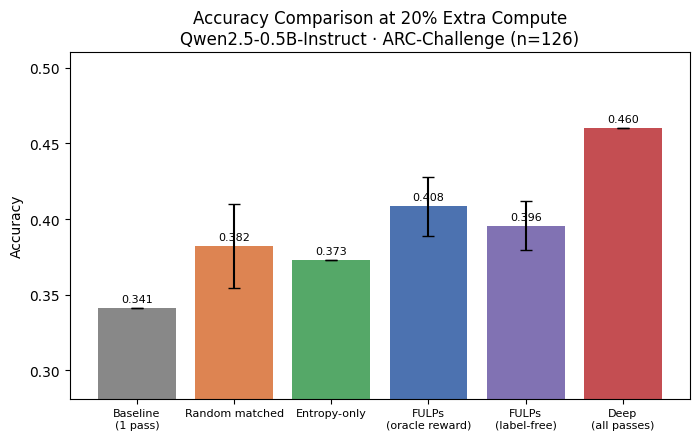

Saved: FULPs_LLM_V1/figures/fig01_accuracy_comparison.png


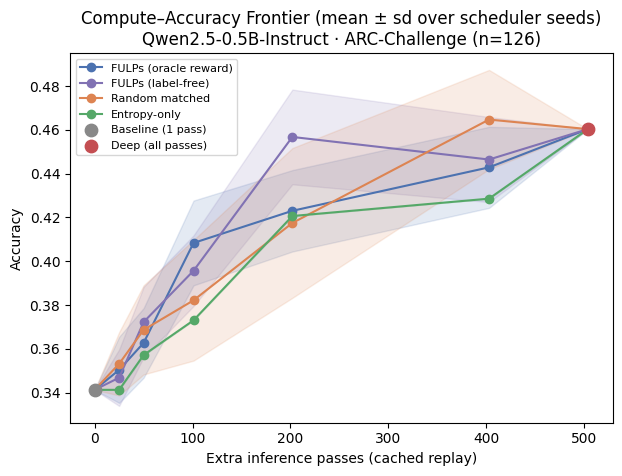

Saved: FULPs_LLM_V1/figures/fig02_compute_accuracy_frontier.png


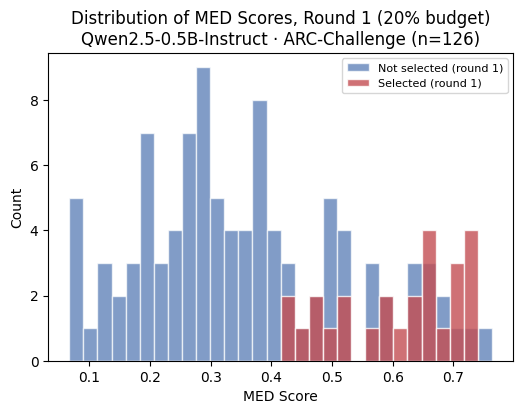

Saved: FULPs_LLM_V1/figures/fig03_scheduler_allocation.png


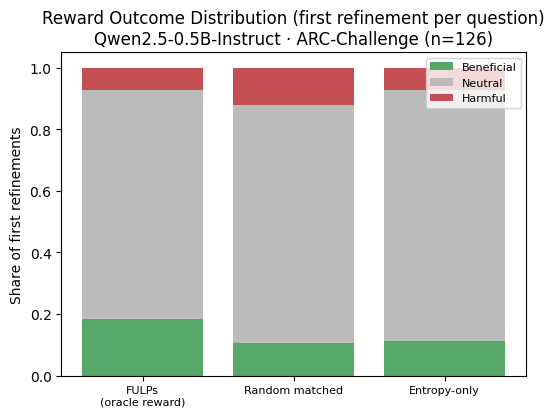

Saved: FULPs_LLM_V1/figures/fig04_reward_outcome_distribution.png


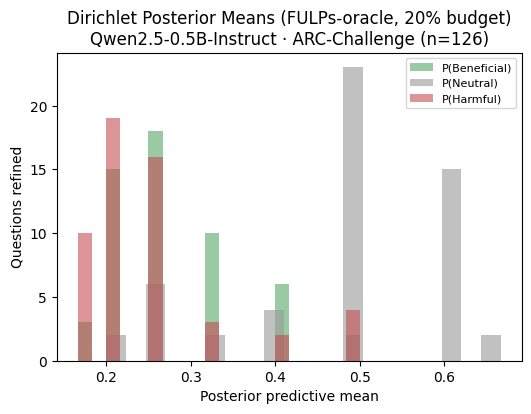

Saved: FULPs_LLM_V1/figures/fig05_dirichlet_posterior.png


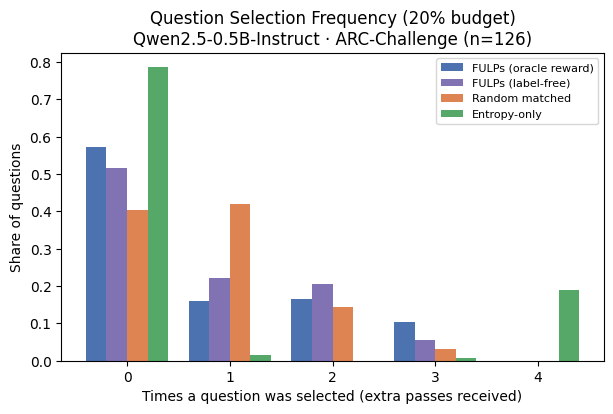

Saved: FULPs_LLM_V1/figures/fig06_question_selection_frequency.png


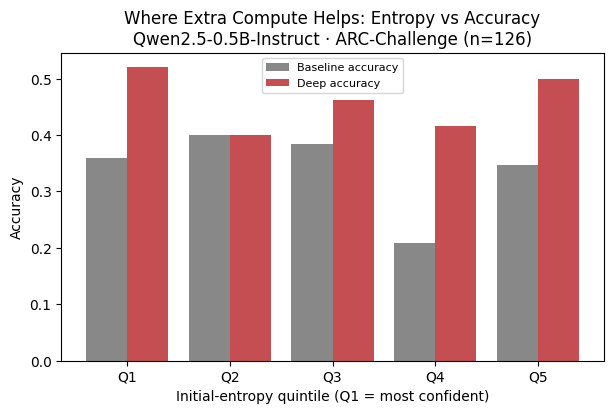

Saved: FULPs_LLM_V1/figures/fig07_entropy_accuracy_relationship.png


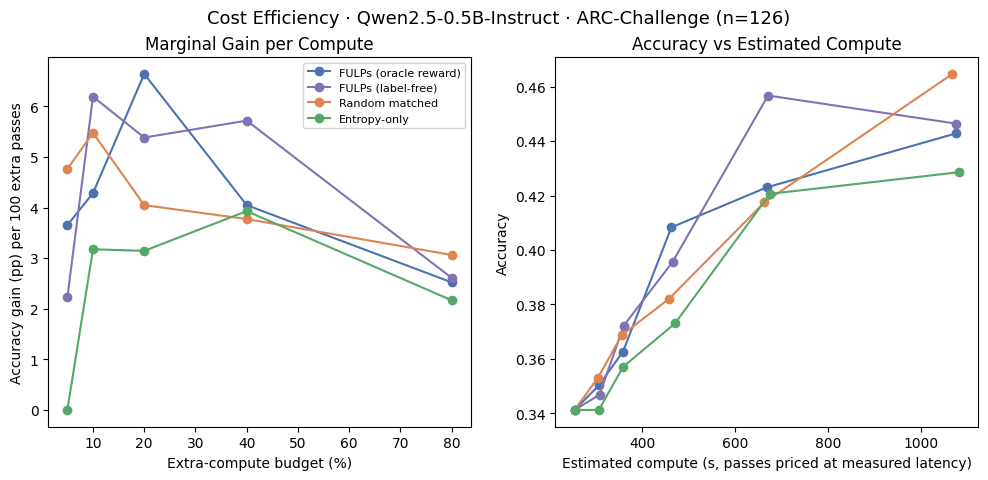

Saved: FULPs_LLM_V1/figures/fig08_cost_efficiency.png


In [17]:
FIG_DIR = os.path.join(CFG.OUT_DIR, "figures")
TAG = "MOCK DATA" if CFG.MODE == "mock" else f"{CFG.MODEL_NAME.split('/')[-1]} · {CFG.SUBSET} (n={N})"
COLORS = dict(baseline="#888888", fulps_oracle="#4C72B0", fulps_labelfree="#8172B3",
              random="#DD8452", entropy="#55A868", deep="#C44E52")
LABELS = dict(baseline="Baseline (1 pass)", fulps_oracle="FULPs (oracle reward)", fulps_labelfree="FULPs (label-free)",
              random="Random matched", entropy="Entropy-only", deep="Deep (all passes)")
FIG_PATHS = []


def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show(); plt.close(fig)
    FIG_PATHS.append(path); print("Saved:", path)


def acc_ms(arm, level):
    if arm == "baseline": return BASE_ACC, 0.0
    if arm == "deep":     return DEEP_ACC, 0.0
    v = RES[(RES.arm == arm) & (RES.level == level)].accuracy.values
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)


def fig01_accuracy_comparison():
    arms = ["baseline", "random", "entropy", "fulps_oracle", "fulps_labelfree", "deep"]
    ms = [acc_ms(a, LV) for a in arms]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(range(len(arms)), [m for m, _ in ms], yerr=[s for _, s in ms], capsize=4, color=[COLORS[a] for a in arms])
    for i, (m, _) in enumerate(ms): ax.text(i, m + 0.004, f"{m:.3f}", ha="center", fontsize=8)
    lo = max(0, min(m for m, _ in ms) - 0.06); ax.set_ylim(lo, min(1, max(m for m, _ in ms) + 0.05))
    ax.set_xticks(range(len(arms))); ax.set_xticklabels([LABELS[a].replace(" (", "\n(") for a in arms], fontsize=8)
    ax.set_ylabel("Accuracy"); ax.set_title(f"Accuracy Comparison at {int(LV*100)}% Extra Compute\n{TAG}")
    save_fig(fig, "fig01_accuracy_comparison.png")


def fig02_compute_accuracy_frontier():
    fig, ax = plt.subplots(figsize=(7, 4.8))
    full = N * CFG.N_EXTRA_PASSES
    for arm in ARMS:
        d = RES[RES.arm == arm].groupby("level").agg(x=("extra_passes", "mean"), m=("accuracy", "mean"), s=("accuracy", "std")).reset_index()
        x = np.r_[0, d.x.values, full]; m = np.r_[BASE_ACC, d.m.values, DEEP_ACC]; s = np.r_[0, d.s.fillna(0).values, 0]
        ax.plot(x, m, marker="o", color=COLORS[arm], label=LABELS[arm]); ax.fill_between(x, m - s, m + s, color=COLORS[arm], alpha=0.15)
    ax.scatter([0], [BASE_ACC], color=COLORS["baseline"], s=80, zorder=5, label=LABELS["baseline"])
    ax.scatter([full], [DEEP_ACC], color=COLORS["deep"], s=80, zorder=5, label=LABELS["deep"])
    ax.set_xlabel("Extra inference passes (cached replay)"); ax.set_ylabel("Accuracy")
    ax.set_title(f"Compute–Accuracy Frontier (mean ± sd over scheduler seeds)\n{TAG}"); ax.legend(fontsize=8)
    save_fig(fig, "fig02_compute_accuracy_frontier.png")


def fig03_scheduler_allocation():
    a = ARR[("fulps_oracle", LV, 0)]; med, sel = a["med0"], a["sel0"]
    mask = np.zeros(N, bool); mask[sel] = True
    fig, ax = plt.subplots(figsize=(6, 4)); bins = np.linspace(med.min(), med.max(), 31)
    ax.hist(med[~mask], bins=bins, color="#4C72B0", edgecolor="white", alpha=0.7, label="Not selected (round 1)")
    ax.hist(med[mask], bins=bins, color="#C44E52", edgecolor="white", alpha=0.8, label="Selected (round 1)")
    ax.set_xlabel("MED Score"); ax.set_ylabel("Count"); ax.legend(fontsize=8)
    ax.set_title(f"Distribution of MED Scores, Round 1 ({int(LV*100)}% budget)\n{TAG}")
    save_fig(fig, "fig03_scheduler_allocation.png")


def fig04_reward_outcome_distribution():
    arms = ["fulps_oracle", "random", "entropy"]
    fig, ax = plt.subplots(figsize=(6, 4.2)); bottom = np.zeros(len(arms))
    shares = []
    for a in arms:
        fc = ARR[(a, LV, 0)]["first_cat"]; fc = fc[fc >= 0]; shares.append([np.mean(fc == c) for c in (BEN, NEU, HARM)])
    shares = np.array(shares)
    for c, (name, col) in enumerate([("Beneficial", "#55A868"), ("Neutral", "#BBBBBB"), ("Harmful", "#C44E52")]):
        ax.bar(range(len(arms)), shares[:, c], bottom=bottom, color=col, label=name); bottom += shares[:, c]
    ax.set_xticks(range(len(arms))); ax.set_xticklabels([LABELS[a].replace(" (", "\n(") for a in arms], fontsize=8)
    ax.set_ylabel("Share of first refinements"); ax.legend(fontsize=8, loc="upper right")
    ax.set_title(f"Reward Outcome Distribution (first refinement per question)\n{TAG}")
    save_fig(fig, "fig04_reward_outcome_distribution.png")


def fig05_dirichlet_posterior():
    pm = ARR[("fulps_oracle", LV, 0)]["post_mean"]; seen = ARR[("fulps_oracle", LV, 0)]["done"] > 0
    fig, ax = plt.subplots(figsize=(6, 4))
    for c, (name, col) in enumerate([("P(Beneficial)", "#55A868"), ("P(Neutral)", "#999999"), ("P(Harmful)", "#C44E52")]):
        ax.hist(pm[seen, c], bins=20, alpha=0.6, color=col, label=name)
    ax.set_xlabel("Posterior predictive mean"); ax.set_ylabel("Questions refined")
    ax.set_title(f"Dirichlet Posterior Means (FULPs-oracle, {int(LV*100)}% budget)\n{TAG}"); ax.legend(fontsize=8)
    save_fig(fig, "fig05_dirichlet_posterior.png")


def fig06_question_selection_frequency():
    arms = ["fulps_oracle", "fulps_labelfree", "random", "entropy"]; w = 0.2
    fig, ax = plt.subplots(figsize=(7, 4))
    for j, a in enumerate(arms):
        dn = ARR[(a, LV, 0)]["done"]; ax.bar(np.arange(CFG.N_EXTRA_PASSES + 1) + (j - 1.5) * w,
                                             [np.mean(dn == k) for k in range(CFG.N_EXTRA_PASSES + 1)], w, color=COLORS[a], label=LABELS[a])
    ax.set_xlabel("Times a question was selected (extra passes received)"); ax.set_ylabel("Share of questions")
    ax.set_title(f"Question Selection Frequency ({int(LV*100)}% budget)\n{TAG}"); ax.legend(fontsize=8)
    save_fig(fig, "fig06_question_selection_frequency.png")


def fig07_entropy_accuracy_relationship():
    q = np.quantile(H[:, 0], np.linspace(0, 1, 6)); b = np.clip(np.searchsorted(q, H[:, 0], side="right") - 1, 0, 4)
    fig, ax = plt.subplots(figsize=(7, 4)); x = np.arange(5)
    ax.bar(x - 0.2, [CORRECT[b == i, 0].mean() for i in range(5)], 0.4, color=COLORS["baseline"], label="Baseline accuracy")
    ax.bar(x + 0.2, [CORRECT[b == i, -1].mean() for i in range(5)], 0.4, color=COLORS["deep"], label="Deep accuracy")
    ax.set_xticks(x); ax.set_xticklabels([f"Q{i+1}" for i in range(5)])
    ax.set_xlabel("Initial-entropy quintile (Q1 = most confident)"); ax.set_ylabel("Accuracy"); ax.legend(fontsize=8)
    ax.set_title(f"Where Extra Compute Helps: Entropy vs Accuracy\n{TAG}")
    save_fig(fig, "fig07_entropy_accuracy_relationship.png")


def fig08_cost_efficiency():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for arm in ARMS:
        d = RES[RES.arm == arm].groupby("level").agg(g=("gain_pp_per_100_passes", "mean"), e=("est_compute_s", "mean"), a=("accuracy", "mean")).reset_index()
        axes[0].plot(d.level * 100, d.g, marker="o", color=COLORS[arm], label=LABELS[arm])
        axes[1].plot(np.r_[LATC[:, 0].sum(), d.e], np.r_[BASE_ACC, d.a], marker="o", color=COLORS[arm], label=LABELS[arm])
    axes[0].set_xlabel("Extra-compute budget (%)"); axes[0].set_ylabel("Accuracy gain (pp) per 100 extra passes"); axes[0].set_title("Marginal Gain per Compute")
    axes[1].set_xlabel("Estimated compute (s, passes priced at measured latency)"); axes[1].set_ylabel("Accuracy"); axes[1].set_title("Accuracy vs Estimated Compute")
    axes[0].legend(fontsize=8); fig.suptitle(f"Cost Efficiency · {TAG}", fontsize=13)
    save_fig(fig, "fig08_cost_efficiency.png")


for f in (fig01_accuracy_comparison, fig02_compute_accuracy_frontier, fig03_scheduler_allocation,
          fig04_reward_outcome_distribution, fig05_dirichlet_posterior, fig06_question_selection_frequency,
          fig07_entropy_accuracy_relationship, fig08_cost_efficiency):
    f()

## 11. Compute accounting and reproducibility record

In [18]:
sched = RES[RES.arm.isin(ARMS)]
ACCOUNTING = {
    "1. Live inference (cache build), seconds": round(LIVE_BUILD_S, 1) if CFG.MODE != "mock" else "n/a (mock)",
    "   mean measured latency per pass (s)": round(float(LAT.mean()), 4) if CFG.MODE != "mock" else f"{LAT.mean():.3f} (synthetic)",
    "2. Passes: baseline / full extra / deep total": f"{N} / {N * CFG.N_EXTRA_PASSES} / {N * N_PASSES}",
    "3. Cached replay, all runs (s)": round(REPLAY_S, 2),
    "4. Estimated compute, baseline (s)": round(float(LATC[:, 0].sum()), 1),
    "   estimated compute, deep (s)": round(float(LATC[:, -1].sum()), 1),
    "5. Scheduler overhead per run, FULPs mean (s)": round(float(sched[sched.arm.isin(FULPS_ARMS)].overhead_s.mean()), 5),
    "   overhead per run, random / entropy (s)": f"{sched[sched.arm=='random'].overhead_s.mean():.5f} / {sched[sched.arm=='entropy'].overhead_s.mean():.5f}",
    "6. Graph construction (s)": round(GRAPH["seconds"], 4),
    "7. End-to-end notebook runtime so far (s)": round(time.perf_counter() - T_NOTEBOOK_START, 1),
}
for k, v in ACCOUNTING.items(): print(f"{k:55s} {v}")

# ---- reproducibility artifacts ----
cfg_dump = asdict(CFG); cfg_dump.update(perms=PERMS.tolist(), scheduler_seeds=list(range(CFG.N_SCHED_SEEDS)),
                                         sample_ids=[it["id"] for it in ITEMS], torch=torch.__version__)
json.dump(cfg_dump, open(os.path.join(CFG.OUT_DIR, "config_and_reproducibility.json"), "w"), indent=1, default=str)

a0 = ARR[("fulps_oracle", LV, 0)]
QTAB = pd.DataFrame(dict(id=[it["id"] for it in ITEMS], gold=GOLD, base_pred=AGG[:, 0].argmax(-1),
                         base_correct=CORRECT[:, 0], deep_correct=CORRECT[:, -1], entropy0=H[:, 0],
                         attention_A=ATT.numpy(), degree=GRAPH["deg_out"]))
for arm in ARMS:
    QTAB[f"{arm}_refinements"] = ARR[(arm, LV, 0)]["done"]; QTAB[f"{arm}_final_correct"] = ARR[(arm, LV, 0)]["final_correct"]
QTAB[["post_P_beneficial", "post_P_neutral", "post_P_harmful"]] = a0["post_mean"]
QTAB[["conc_B", "conc_N", "conc_H"]] = a0["conc"]
QTAB.to_csv(os.path.join(CFG.OUT_DIR, "question_level_results.csv"), index=False)

print("\nFigures:"); [print("  ", p) for p in FIG_PATHS]
print("Outputs in:", os.path.abspath(CFG.OUT_DIR))

1. Live inference (cache build), seconds                423.3
   mean measured latency per pass (s)                   2.0195
2. Passes: baseline / full extra / deep total           126 / 504 / 630
3. Cached replay, all runs (s)                          0.39
4. Estimated compute, baseline (s)                      254.5
   estimated compute, deep (s)                          1272.3
5. Scheduler overhead per run, FULPs mean (s)           0.001
   overhead per run, random / entropy (s)               0.00013 / 0.00009
6. Graph construction (s)                               0.0517
7. End-to-end notebook runtime so far (s)               1513.2

Figures:
   FULPs_LLM_V1/figures/fig01_accuracy_comparison.png
   FULPs_LLM_V1/figures/fig02_compute_accuracy_frontier.png
   FULPs_LLM_V1/figures/fig03_scheduler_allocation.png
   FULPs_LLM_V1/figures/fig04_reward_outcome_distribution.png
   FULPs_LLM_V1/figures/fig05_dirichlet_posterior.png
   FULPs_LLM_V1/figures/fig06_question_selection_frequency.p

## 12. Limitations (read before quoting any result)

- **One model, one benchmark, one sample.** Nothing here shows generalization to other LLMs, tasks, or larger N.
- **Oracle reward ≠ deployable.** `fulps_oracle` updates on ground-truth correctness. Only `fulps_labelfree` is label-free, and its reward (entropy change) can reward confident wrong answers; `entropy_down_but_worse` counts those.
- **Cached replay.** All scheduler seeds re-use one set of model outputs. They quantify scheduler randomness, not model variance. Runtime for scheduled arms is *estimated* from measured per-pass latency, not measured end to end. Latency is amortized over each batch.
- **Attention is not learned.** `A_i` equals inverse graph degree (see audit); it behaves as a "peripheral question" signal on this kNN graph.
- **Per-node posteriors see at most 4 observations**, so the Thompson component learns little per node; selection is largely MED plus noise.
- **Power.** At small budgets, arms differ on a handful of questions; McNemar can only resolve differences when discordant pairs are numerous. Use the CIs, not only p-values.
- **Dataset revision is not pinned** (fingerprint is printed). Position bias in the model is partly corrected by permutation averaging, which is part of why Deep beats Baseline.
- **Graph normalization** (Â) is computed per spec but unused by this adapter.

## 13. Code-reuse audit

| Component | Status |
|---|---|
| `scheduler.py` cell: `LAMBDA`, `ALPHA`, `MED_WEIGHTS`, `compute_uncertainty`, `CostTracker`, `BudgetTracker`, `compute_beu`, `compute_med`, `laplace_smooth`, `ThompsonSampler` | **Reused unchanged** (copied verbatim, called directly) |
| `GATAttentionScorer` | **Reused unchanged** (untrained, as in the original) |
| `ThompsonSampler.select_nodes` / `update_from_outcome` | **Modified** in subclass `DirichletThompsonSampler`: one line (`sampled`) changed in `select_nodes`; update rule replaced with one-hot Dirichlet counts. Reason: spec requires a 3-category reward, and the original samples Beta inline so it cannot be hooked. |
| Original plotting code (`plot_*`, `_plot_full_and_aggregate`, `_plot_interaction_figure`) | **Style reused** (palette, panel sizes, title conventions); **function bodies not reused** because those functions are tied to baseline-vs-scheduled run DataFrames, and these figures plot different quantities. |
| Original stats (`compute_v1_statistics`, chi-square McNemar) | **Replaced** by exact McNemar + Holm + bootstrap, per spec (exact test is preferred for small discordant counts). |
| `GCN`, `ScheduledGCN`, `DeepGCN`, `train_*`, `batch_runner*`, `load_real_data` | **Not used** (GNN-specific). |
| New | LLM backend, prompts, permutation mapping and aggregation, kNN graph, arms/replay runner, label-free reward, statistics, 8 figures, accounting. |